# HW1 – Introduction à l'apprenabilité

## Apprentissage statistique et automatique

### Objectif du devoir

L'objectif de ce travail est d'étudier expérimentalement
les différences entre les cadres d'apprentissage PAC et
PAC agnostique.

Pour cela, nous utilisons une classe d'hypothèses
constituée de classifieurs à seuil et implémentons
un algorithme de minimisation du risque empirique (ERM).

Nous étudierons d'abord le cas réalisable, sans bruit,
puis le cas agnostique, avec du bruit sur les étiquettes.

## 1. Génération des données

Dans cette première partie, je génère des échantillons de différentes tailles à partir d'une distribution uniforme sur l'intervalle [0,1].

J'ai choisi un seuil réel θ = 0.6 pour attribuer les étiquettes aux observations. Les points supérieurs à ce seuil appartiennent à la classe 1, et les autres à la classe 0.

Je commence par étudier le cas réalisable, sans bruit dans les étiquettes.

In [46]:
import numpy as np
import matplotlib.pyplot as plt

# Définition du seuil réel
theta = 0.6

# Tailles des échantillons demandées
tailles_echantillons = [5, 10, 20, 50, 100, 200]

# Générateur aléatoire pour des résultats reproductibles
rng = np.random.default_rng(42)


In [47]:
def generer_donnees(m, theta, rng):
    # Générer m valeurs aléatoires entre 0 et 1
    X = rng.uniform(0, 1, m)

    # Attribuer une classe selon le seuil theta
    y = (X > theta).astype(int)

    return X, y


In [48]:
# Dictionnaire pour stocker les jeux de données
jeux_donnees = {}

for m in tailles_echantillons:
    X, y = generer_donnees(m, theta, rng)
    jeux_donnees[m] = (X, y)

    print(f"Taille m = {m} : {len(X)} observations générées")


Taille m = 5 : 5 observations générées
Taille m = 10 : 10 observations générées
Taille m = 20 : 20 observations générées
Taille m = 50 : 50 observations générées
Taille m = 100 : 100 observations générées
Taille m = 200 : 200 observations générées


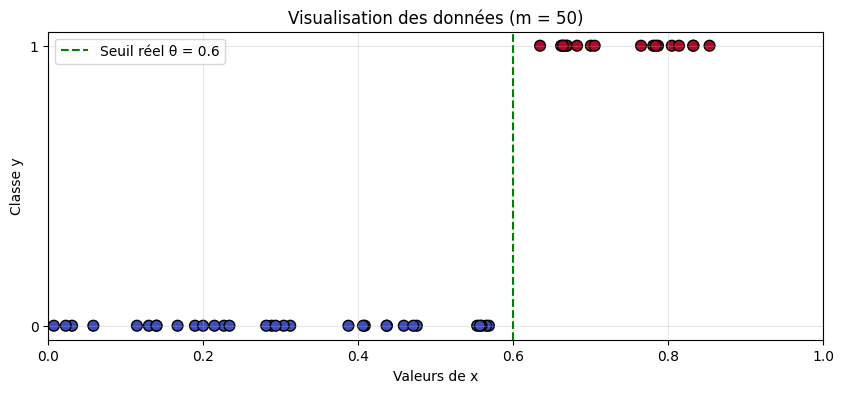

In [49]:
# Sélectionner l'échantillon de taille 50
X, y = jeux_donnees[50]

plt.figure(figsize=(10, 4))

# Afficher les points selon leur classe
plt.scatter(X, y, c=y, cmap="coolwarm",
            edgecolors="black", s=60)

# Afficher le vrai seuil
plt.axvline(theta, color="green", linestyle="--",
            label=f"Seuil réel θ = {theta}")

plt.xlabel("Valeurs de x")
plt.ylabel("Classe y")
plt.title("Visualisation des données (m = 50)")

plt.yticks([0, 1])
plt.xlim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### Interprétation des données générées

Pour cette première expérience, j'ai choisi un seuil θ = 0.6 et généré 50 observations aléatoires sur l'intervalle [0,1].

Sur le graphique, je remarque que tous les points situés à gauche du seuil appartiennent à la classe 0, tandis que ceux situés à droite appartiennent à la classe 1.

On observe donc une séparation nette entre les deux classes. C'est normal puisque les étiquettes ont été générées directement à partir du seuil choisi, sans ajouter de bruit.

Cette première partie correspond ainsi au cas réalisable du PAC Learning, où il existe au moins une hypothèse capable de classer correctement toutes les observations.

## 2. Implémentation de l'algorithme ERM

Dans cette partie, je cherche à retrouver un seuil à partir des observations et de leurs étiquettes, sans utiliser la valeur du seuil réel pendant l'apprentissage.

Pour cela, j'implémente l'algorithme ERM (Empirical Risk Minimization), dont le principe est de choisir l'hypothèse qui minimise l'erreur sur les données d'entraînement.

In [50]:
def predire(X, seuil):
    # Attribuer la classe 1 si x > seuil, sinon 0
    return (X > seuil).astype(int)


In [51]:
def erreur_empirique(y_reel, y_predit):
    # Proportion de prédictions incorrectes
    return np.mean(y_reel != y_predit)


### Stratégie de recherche du seuil optimal

Pour implémenter l'ERM, j'ai choisi de tester plusieurs seuils candidats et de conserver celui qui minimise l'erreur empirique.

Au lieu de tester toutes les valeurs possibles entre 0 et 1, je commence par trier les observations. Je calcule ensuite les milieux entre deux valeurs consécutives, en ajoutant les bornes 0 et 1.

Cette méthode permet de considérer les différentes séparations possibles entre les observations, car les prédictions ne changent pas tant que le seuil reste entre deux valeurs consécutives.

Pour chaque seuil candidat, je calcule la proportion d'observations mal classées :

$$
L_S(h_t)=\frac{1}{m}\sum_{i=1}^{m}\mathbf{1}[h_t(x_i)\neq y_i]
$$

Je sélectionne finalement le seuil qui donne la plus petite erreur empirique.

Cette approche permet de rechercher un seuil optimal sur l'échantillon, sans utiliser directement la valeur du seuil réel θ.

In [52]:
def erm_seuil(X, y):
    # Trier les valeurs de X
    X_trie = np.sort(np.unique(X))

    # Construire les seuils candidats
    seuils = np.concatenate((
        [0],
        (X_trie[:-1] + X_trie[1:]) / 2,
        [1]
    ))

    meilleur_seuil = None
    erreur_min = float("inf")

    # Chercher le seuil qui minimise l'erreur
    for seuil in seuils:
        y_predit = predire(X, seuil)
        erreur = erreur_empirique(y, y_predit)

        if erreur < erreur_min:
            erreur_min = erreur
            meilleur_seuil = seuil

    return meilleur_seuil, erreur_min


In [53]:
X, y = jeux_donnees[50]

seuil_appris, erreur = erm_seuil(X, y)

print(f"Seuil réel : {theta}")
print(f"Seuil appris par ERM : {seuil_appris:.4f}")
print(f"Erreur empirique : {erreur:.4f}")


Seuil réel : 0.6
Seuil appris par ERM : 0.6017
Erreur empirique : 0.0000


### Interprétation des résultats de l'ERM

Pour un échantillon de 50 observations, l'algorithme ERM a trouvé un seuil de 0.6017, alors que le seuil réel utilisé pour générer les données est de 0.6.

Je remarque que les deux valeurs sont très proches. L'erreur empirique obtenue est nulle, ce qui signifie que toutes les observations de l'échantillon d'entraînement sont correctement classées.

Ce résultat montre que l'algorithme a réussi à trouver un seuil adapté aux données disponibles. Cependant, une erreur nulle sur l'entraînement ne garantit pas nécessairement une erreur nulle sur de nouvelles données. Il faudra donc évaluer le modèle sur un autre échantillon.

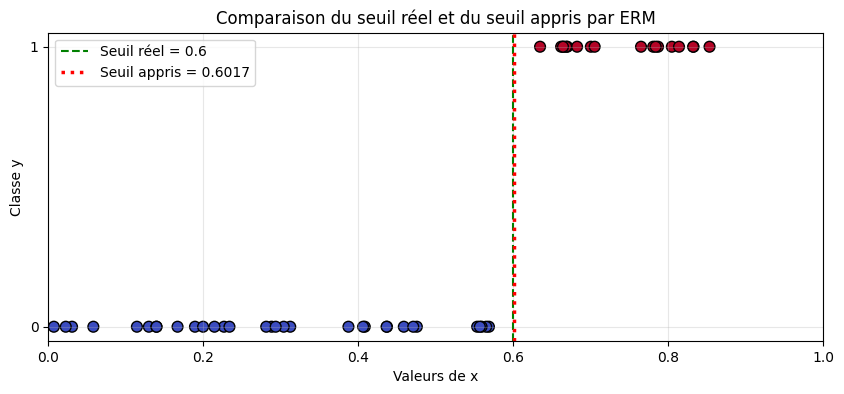

In [54]:

plt.figure(figsize=(10, 4))

# Visualiser les observations
plt.scatter(X, y, c=y, cmap="coolwarm",
            edgecolors="black", s=60)

# Seuil réel
plt.axvline(theta, color="green", linestyle="--",
            label=f"Seuil réel = {theta}")

# Seuil appris
plt.axvline(seuil_appris, color="red", linestyle=":",
            linewidth=2.5,
            label=f"Seuil appris = {seuil_appris:.4f}")

plt.xlabel("Valeurs de x")
plt.ylabel("Classe y")
plt.title("Comparaison du seuil réel et du seuil appris par ERM")

plt.yticks([0, 1])
plt.xlim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 3. Évaluation des performances

Après avoir appris un seuil avec l'ERM, je souhaite vérifier si le modèle fonctionne aussi bien sur de nouvelles observations.

Je vais comparer l'erreur empirique, calculée sur les données d'entraînement, avec l'erreur réelle, estimée à partir d'un grand échantillon de test indépendant.

J'étudierai ensuite l'influence de la taille de l'échantillon sur ces deux erreurs.

In [55]:
# Génération d'un échantillon de test indépendant
X_test, y_test = generer_donnees(100000, theta, rng)

# Prédictions sur les données de test
y_test_predit = predire(X_test, seuil_appris)

# Calcul de l'erreur sur le test
erreur_test = erreur_empirique(y_test, y_test_predit)

# Vraie erreur théorique dans le cas réalisable
erreur_theorique = abs(seuil_appris - theta)

print(f"Erreur empirique : {erreur:.4f}")
print(f"Erreur sur le test : {erreur_test:.4f}")
print(f"Vraie erreur théorique : {erreur_theorique:.4f}")


Erreur empirique : 0.0000
Erreur sur le test : 0.0017
Vraie erreur théorique : 0.0017


### Interprétation des erreurs

Pour évaluer le modèle, j'ai généré un nouvel échantillon de 100 000 observations, indépendant des données d'entraînement.

J'obtiens une erreur empirique de 0, contre une erreur de 0.0017 sur les données de test. Cette dernière est également très proche de la vraie erreur théorique, qui vaut 0.0017.

Je constate donc que le seuil appris permet de bien classer les nouvelles observations. Cependant, même si le modèle ne fait aucune erreur sur les données d'entraînement, il peut encore se tromper sur des données qu'il n'a jamais vues.

Cela montre l'intérêt d'évaluer un modèle sur un échantillon indépendant plutôt que de se limiter à son erreur d'entraînement.

In [56]:
# Stocker les résultats pour chaque taille
resultats = []

for m in tailles_echantillons:

    # Récupérer les données d'entraînement
    X_train, y_train = jeux_donnees[m]

    # Apprendre le seuil avec ERM
    seuil_m, erreur_train = erm_seuil(X_train, y_train)

    # Évaluer sur le même échantillon de test indépendant
    y_predit_test = predire(X_test, seuil_m)
    erreur_test_m = erreur_empirique(y_test, y_predit_test)

    # Enregistrer les résultats
    resultats.append((m, seuil_m, erreur_train, erreur_test_m))

    print(
        f"m = {m:3d} | "
        f"Seuil appris = {seuil_m:.4f} | "
        f"Erreur empirique = {erreur_train:.4f} | "
        f"Erreur test = {erreur_test_m:.4f}"
    )


m =   5 | Seuil appris = 0.5681 | Erreur empirique = 0.0000 | Erreur test = 0.0313
m =  10 | Seuil appris = 0.5471 | Erreur empirique = 0.0000 | Erreur test = 0.0529
m =  20 | Seuil appris = 0.5931 | Erreur empirique = 0.0000 | Erreur test = 0.0070
m =  50 | Seuil appris = 0.6017 | Erreur empirique = 0.0000 | Erreur test = 0.0017
m = 100 | Seuil appris = 0.6091 | Erreur empirique = 0.0000 | Erreur test = 0.0092
m = 200 | Seuil appris = 0.6014 | Erreur empirique = 0.0000 | Erreur test = 0.0013


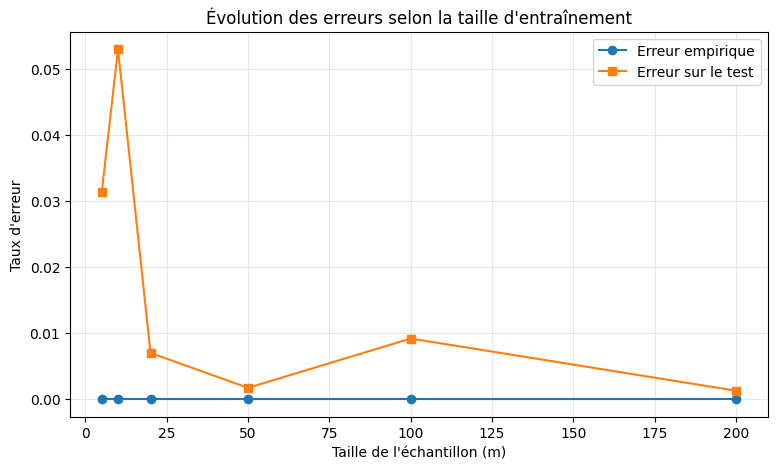

In [57]:
# Récupérer les valeurs calculées
m_valeurs = [r[0] for r in resultats]
erreurs_train = [r[2] for r in resultats]
erreurs_test = [r[3] for r in resultats]

plt.figure(figsize=(9, 5))

plt.plot(m_valeurs, erreurs_train, "o-",
         label="Erreur empirique")

plt.plot(m_valeurs, erreurs_test, "s-",
         label="Erreur sur le test")

plt.xlabel("Taille de l'échantillon (m)")
plt.ylabel("Taux d'erreur")
plt.title("Évolution des erreurs selon la taille d'entraînement")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### Interprétation : influence de la taille de l'échantillon

J'ai comparé les performances de l'algorithme ERM pour différentes tailles d'échantillons, allant de 5 à 200 observations.

Je constate d'abord que l'erreur empirique reste nulle dans tous les cas. Cela s'explique par le fait que les données ont été générées sans bruit et qu'il est donc possible de trouver un seuil qui les classe correctement.

En revanche, l'erreur sur les données de test varie selon la taille de l'échantillon. Par exemple, elle est de 5.29 % pour 10 observations, contre seulement 0.13 % pour 200 observations.

Je remarque aussi que l'erreur ne diminue pas de façon régulière. Pour 100 observations, elle augmente légèrement par rapport à celle obtenue avec 50 observations. Cela peut s'expliquer par le caractère aléatoire des échantillons générés.

Globalement, les résultats suggèrent qu'utiliser davantage de données améliore la généralisation du modèle, mais une seule expérience ne suffit pas pour confirmer cette tendance. Il serait donc intéressant de répéter les expériences plusieurs fois pour observer un comportement plus stable.

## 4. Vérification expérimentale du PAC Learning

Dans cette partie, je répète l'apprentissage 500 fois pour chaque taille d'échantillon afin d'estimer la probabilité que l'erreur réelle dépasse une précision fixée ε.

J'ai choisi ε = 0.05 et δ = 0.05 pour étudier à partir de quelle taille d'échantillon la probabilité d'échec estimée devient inférieure à 5 %.

In [58]:
# Paramètres de l'expérience PAC
epsilon = 0.05
delta = 0.05
nb_repetitions = 500

# Stocker les probabilités estimées
probabilites_pac = []

for m in tailles_echantillons:

    nb_echecs = 0

    for _ in range(nb_repetitions):

        # Générer un nouvel échantillon d'entraînement
        X_train, y_train = generer_donnees(m, theta, rng)

        # Apprendre un seuil avec ERM
        seuil_m, _ = erm_seuil(X_train, y_train)

        # Calculer la vraie erreur théorique
        erreur_vraie = abs(seuil_m - theta)

        # Vérifier si l'erreur dépasse epsilon
        if erreur_vraie > epsilon:
            nb_echecs += 1

    # Estimer la probabilité d'échec
    proba = nb_echecs / nb_repetitions
    probabilites_pac.append(proba)

    print(f"m = {m:3d} | P(L(h) > ε) ≈ {proba:.4f}")


m =   5 | P(L(h) > ε) ≈ 0.5740
m =  10 | P(L(h) > ε) ≈ 0.3600
m =  20 | P(L(h) > ε) ≈ 0.1220
m =  50 | P(L(h) > ε) ≈ 0.0060
m = 100 | P(L(h) > ε) ≈ 0.0000
m = 200 | P(L(h) > ε) ≈ 0.0000


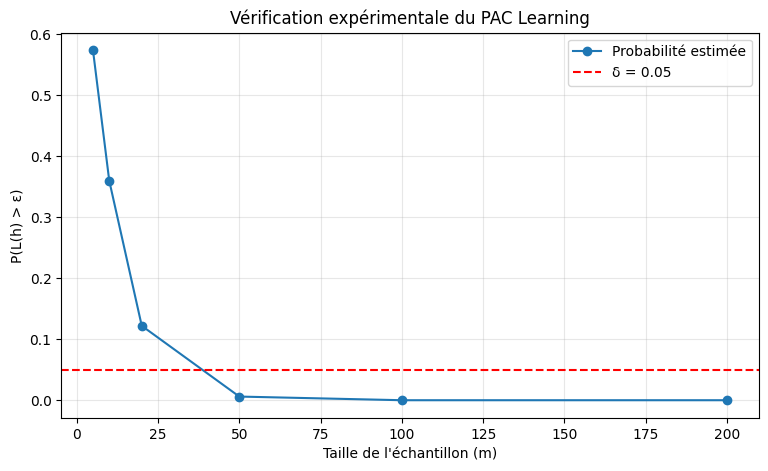

In [59]:
plt.figure(figsize=(9, 5))

plt.plot(tailles_echantillons, probabilites_pac,
         marker="o", label="Probabilité estimée")

# Niveau de confiance choisi
plt.axhline(delta, color="red", linestyle="--",
            label=f"δ = {delta}")

plt.xlabel("Taille de l'échantillon (m)")
plt.ylabel("P(L(h) > ε)")
plt.title("Vérification expérimentale du PAC Learning")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Interprétation de l'expérience PAC

Pour cette expérience, j'ai choisi une précision ε = 0.05 et un niveau de risque δ = 0.05. J'ai ensuite répété l'apprentissage 500 fois pour chaque taille d'échantillon afin d'estimer la probabilité que l'erreur réelle dépasse ε.

Je remarque que cette probabilité diminue fortement lorsque la taille de l'échantillon augmente. Elle passe de 57,4 % pour 5 observations à seulement 0,6 % pour 50 observations.

À partir de 50 observations, la probabilité estimée devient inférieure à δ = 0.05. Pour 100 et 200 observations, je n'ai observé aucun dépassement du seuil ε parmi les 500 répétitions.

Ces résultats illustrent le principe du PAC Learning : en augmentant le nombre de données d'entraînement, on réduit la probabilité d'obtenir un modèle dont l'erreur dépasse la précision souhaitée.

Cette expérience permet aussi de mieux comprendre pourquoi une seule exécution ne suffit pas pour évaluer un algorithme d'apprentissage. Les répétitions donnent une estimation plus fiable de son comportement général.

## 5. Passage au PAC agnostique

Après avoir étudié le cas réalisable, je m'intéresse maintenant au comportement de l'ERM lorsque les données contiennent du bruit.

Pour cela, j'introduis une probabilité η = 0.1 d'inverser chaque étiquette, indépendamment des autres observations.

L'objectif est de voir comment ce bruit influence le seuil appris, l'erreur empirique et la capacité de généralisation du modèle.

In [60]:
def generer_donnees_bruitees(m, theta, eta, rng):

    # Générer les observations entre 0 et 1
    X = rng.uniform(0, 1, m)

    # Créer les étiquettes initiales
    y = (X > theta).astype(int)

    # Déterminer aléatoirement les étiquettes à inverser
    bruit = rng.random(m) < eta

    # Inverser les étiquettes sélectionnées
    y_bruite = y.copy()
    y_bruite[bruit] = 1 - y_bruite[bruit]

    return X, y_bruite


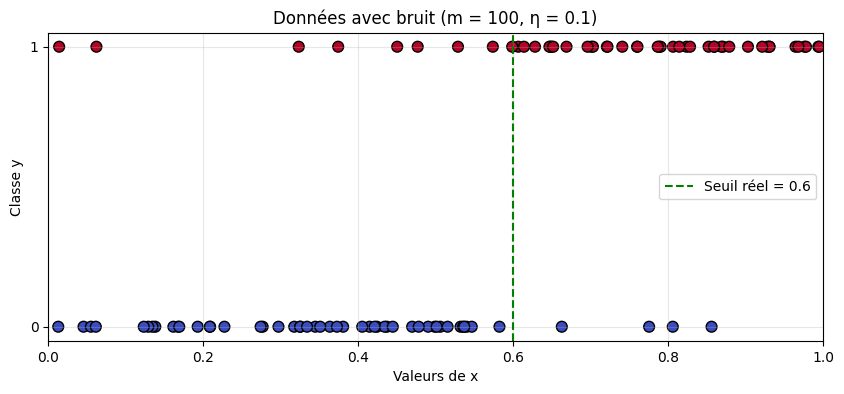

In [61]:

# Taux de bruit choisi
eta = 0.1

# Générer 100 observations bruitées
X_bruit, y_bruit = generer_donnees_bruitees(
    100, theta, eta, rng
)

# Visualisation
plt.figure(figsize=(10, 4))

plt.scatter(X_bruit, y_bruit,
            c=y_bruit, cmap="coolwarm",
            edgecolors="black", s=60)

plt.axvline(theta, color="green", linestyle="--",
            label=f"Seuil réel = {theta}")

plt.xlabel("Valeurs de x")
plt.ylabel("Classe y")
plt.title("Données avec bruit (m = 100, η = 0.1)")

plt.yticks([0, 1])
plt.xlim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Interprétation des données bruitées

Pour étudier le cas agnostique, j'ai choisi d'ajouter un bruit de 10 % sur les étiquettes d'un échantillon de 100 observations.

Contrairement au cas précédent, je remarque que les deux classes ne sont plus parfaitement séparées. Certains points situés à gauche du seuil 0.6 appartiennent à la classe 1, et inversement.

Cela s'explique par l'inversion aléatoire de certaines étiquettes. Dans ce cas, il n'est plus possible de trouver un seuil qui classe correctement toutes les observations.

On passe donc du cadre réalisable à un cadre agnostique, où l'objectif est de trouver le meilleur classifieur possible malgré la présence de bruit.

In [62]:
# Appliquer ERM aux données bruitées
seuil_bruit, erreur_bruit = erm_seuil(X_bruit, y_bruit)

# Afficher les résultats
print(f"Seuil réel : {theta}")
print(f"Seuil appris avec bruit : {seuil_bruit:.4f}")
print(f"Erreur empirique avec bruit : {erreur_bruit:.4f}")


Seuil réel : 0.6
Seuil appris avec bruit : 0.5602
Erreur empirique avec bruit : 0.1200


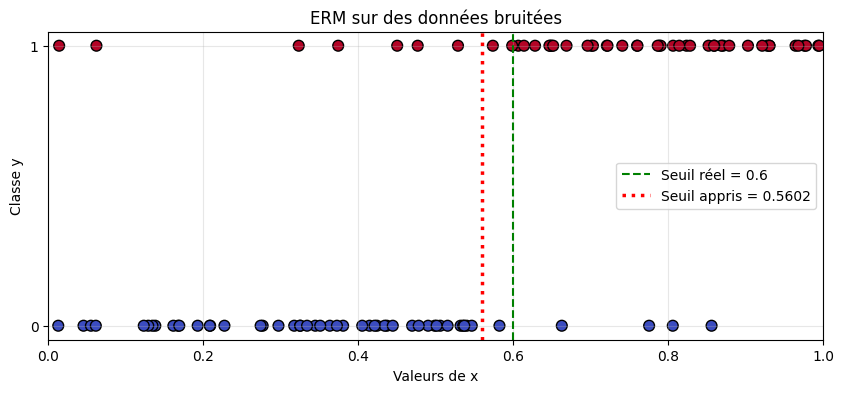

In [63]:
plt.figure(figsize=(10, 4))

# Afficher les données bruitées
plt.scatter(X_bruit, y_bruit,
            c=y_bruit, cmap="coolwarm",
            edgecolors="black", s=60)

# Seuil réel
plt.axvline(theta, color="green", linestyle="--",
            label=f"Seuil réel = {theta}")

# Seuil appris par ERM
plt.axvline(seuil_bruit, color="red", linestyle=":",
            linewidth=2.5,
            label=f"Seuil appris = {seuil_bruit:.4f}")

plt.xlabel("Valeurs de x")
plt.ylabel("Classe y")
plt.title("ERM sur des données bruitées")

plt.yticks([0, 1])
plt.xlim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### Interprétation de l'ERM avec bruit

Après avoir introduit un bruit de 10 % dans les étiquettes, j'ai appliqué le même algorithme ERM sur les 100 observations.

J'obtiens un seuil appris de 0.5602, alors que le seuil réel est de 0.6. Je remarque donc que le seuil estimé s'est légèrement éloigné du seuil initial.

L'erreur empirique est maintenant de 12 %, contrairement au cas sans bruit où elle était nulle. Cela s'explique par la présence d'étiquettes inversées qui empêchent une séparation parfaite des deux classes.

Même si l'algorithme ne parvient plus à classer correctement toutes les observations, il continue à rechercher le seuil qui minimise le nombre d'erreurs.

Cette expérience montre que dans le cas agnostique, l'objectif n'est plus nécessairement d'obtenir une erreur nulle, mais de trouver un modèle qui reste performant malgré le bruit.


### Justification de l'erreur réelle avec bruit

Dans le cas agnostique, j'ai utilisé une formule qui tient compte du taux de bruit et de la différence entre le seuil appris et le seuil réel.

Lorsque le modèle prédit correctement la classe initiale, il peut quand même faire une erreur si l'étiquette est inversée, avec une probabilité η.

À l'inverse, lorsque le modèle se trompe par rapport à la classe initiale, l'inversion de l'étiquette peut rendre sa prédiction correcte.

Comme les observations sont uniformément distribuées sur [0,1], la proportion de désaccord entre les deux seuils correspond à leur distance :

$$
d = |\hat{\theta} - \theta|
$$

L'erreur réelle avec bruit s'écrit alors :

$$
L_\eta(h) = \eta(1-d) + (1-\eta)d
$$

En simplifiant, on obtient :

$$
L_\eta(h) = \eta + (1-2\eta)|\hat{\theta}-\theta|
$$

Avec le taux de bruit choisi, η = 0.1, l'erreur minimale théorique est de 10 %. Elle est atteinte lorsque le seuil appris est égal au seuil réel.

Cette formule me permet de calculer directement l'erreur réelle lors des répétitions, sans générer un grand échantillon de test à chaque fois.


In [64]:
def erreur_reelle_bruitee(seuil_appris, theta, eta):
    # Erreur théorique avec bruit symétrique
    return eta + (1 - 2 * eta) * abs(seuil_appris - theta)


In [65]:
# Résultats du cas agnostique
probabilites_agnostique = []
erreurs_moyennes_agnostique = []

for m in tailles_echantillons:

    nb_echecs = 0
    erreurs = []

    for _ in range(nb_repetitions):

        # Générer un nouvel échantillon bruité
        X_train, y_train = generer_donnees_bruitees(
            m, theta, eta, rng
        )

        # Apprendre le meilleur seuil par ERM
        seuil_m, _ = erm_seuil(X_train, y_train)

        # Calculer l'erreur réelle avec bruit
        erreur_reelle = erreur_reelle_bruitee(
            seuil_m, theta, eta
        )

        erreurs.append(erreur_reelle)

        # Calculer l'excès d'erreur par rapport au meilleur modèle
        exces_erreur = erreur_reelle - eta

        if exces_erreur > epsilon:
            nb_echecs += 1

    proba = nb_echecs / nb_repetitions

    probabilites_agnostique.append(proba)
    erreurs_moyennes_agnostique.append(np.mean(erreurs))

    print(
        f"m = {m:3d} | "
        f"P(L(h) - L* > ε) ≈ {proba:.4f} | "
        f"Erreur réelle moyenne = {np.mean(erreurs):.4f}"
    )


m =   5 | P(L(h) - L* > ε) ≈ 0.6520 | Erreur réelle moyenne = 0.2257
m =  10 | P(L(h) - L* > ε) ≈ 0.4140 | Erreur réelle moyenne = 0.1776
m =  20 | P(L(h) - L* > ε) ≈ 0.2460 | Erreur réelle moyenne = 0.1391
m =  50 | P(L(h) - L* > ε) ≈ 0.0520 | Erreur réelle moyenne = 0.1155
m = 100 | P(L(h) - L* > ε) ≈ 0.0140 | Erreur réelle moyenne = 0.1081
m = 200 | P(L(h) - L* > ε) ≈ 0.0000 | Erreur réelle moyenne = 0.1038


## 6. Comparaison entre PAC et PAC agnostique

Pour terminer les expériences, je compare les résultats obtenus avec et sans bruit.

Je m'intéresse particulièrement à l'évolution des probabilités d'échec et à l'erreur réelle moyenne dans le cas agnostique, afin de mieux comprendre l'influence du bruit sur l'apprentissage.

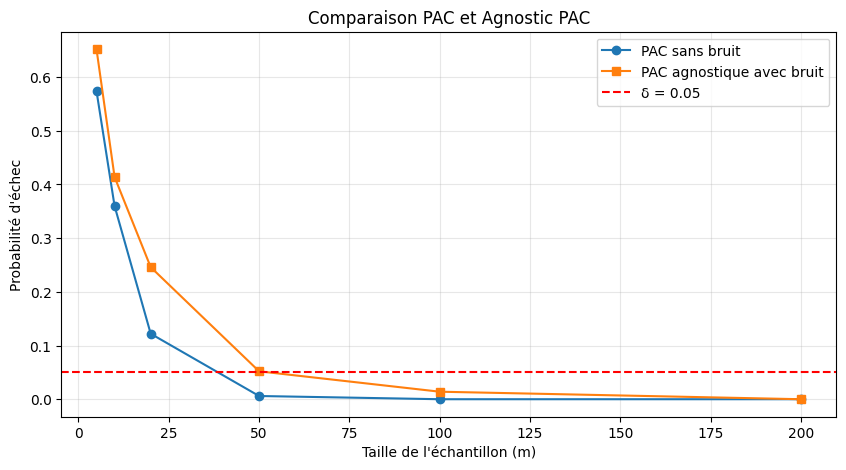

In [66]:
plt.figure(figsize=(10, 5))

plt.plot(
    tailles_echantillons,
    probabilites_pac,
    "o-",
    label="PAC sans bruit"
)

plt.plot(
    tailles_echantillons,
    probabilites_agnostique,
    "s-",
    label="PAC agnostique avec bruit"
)

plt.axhline(
    delta,
    color="red",
    linestyle="--",
    label=f"δ = {delta}"
)

plt.xlabel("Taille de l'échantillon (m)")
plt.ylabel("Probabilité d'échec")
plt.title("Comparaison PAC et Agnostic PAC")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Comparaison entre PAC et PAC agnostique

Pour comparer les deux cadres d'apprentissage, j'ai réalisé 500 répétitions pour chaque taille d'échantillon, en conservant les mêmes paramètres ε = 0.05 et δ = 0.05.

Sur le graphique, je remarque que la probabilité d'échec diminue dans les deux cas lorsque le nombre d'observations augmente.

Cependant, en présence de bruit, cette probabilité reste généralement plus élevée. Par exemple, pour 20 observations, elle est de 12,2 % dans le cas sans bruit, contre 24,6 % dans le cas agnostique.

Je constate également que, dans mon expérience, la probabilité d'échec passe sous 5 % à partir de 50 observations dans le cas réalisable, alors qu'il faut atteindre 100 observations dans le cas agnostique.

Ces résultats montrent que l'ajout de bruit rend l'apprentissage plus difficile. L'algorithme a besoin de davantage de données pour obtenir une précision et un niveau de confiance comparables.

Il faut toutefois distinguer les critères utilisés : dans le cas PAC, j'évalue la probabilité que l'erreur réelle dépasse ε, tandis que dans le cas agnostique, je considère le dépassement de ε par rapport à la meilleure erreur possible.

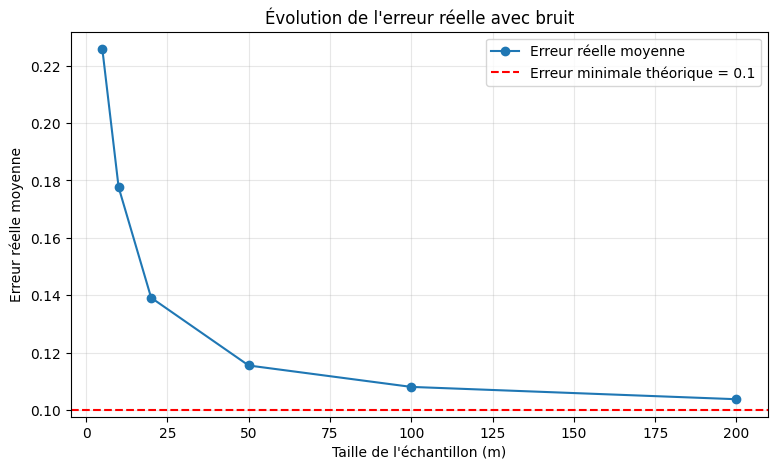

In [67]:
plt.figure(figsize=(9, 5))

# Évolution de l'erreur réelle moyenne
plt.plot(
    tailles_echantillons,
    erreurs_moyennes_agnostique,
    "o-",
    label="Erreur réelle moyenne"
)

# Erreur minimale théorique
plt.axhline(
    eta,
    color="red",
    linestyle="--",
    label=f"Erreur minimale théorique = {eta}"
)

plt.xlabel("Taille de l'échantillon (m)")
plt.ylabel("Erreur réelle moyenne")
plt.title("Évolution de l'erreur réelle avec bruit")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Interprétation de l'évolution de l'erreur réelle

Sur ce dernier graphique, j'observe que l'erreur réelle moyenne diminue progressivement lorsque le nombre d'observations augmente.

Pour 5 observations, l'erreur est d'environ 22,57 %, alors qu'elle atteint seulement 10,38 % pour 200 observations.

Je remarque également que la courbe se rapproche de la ligne rouge correspondant à l'erreur minimale théorique de 10 %, sans atteindre zéro.

Cela montre que même avec des données bruitées, l'algorithme ERM arrive à améliorer ses prédictions lorsqu'il dispose de davantage d'exemples. Cependant, le bruit introduit une limite à la précision qu'il est possible d'obtenir.

Cette observation confirme la différence avec le cas réalisable : dans le cadre agnostique, l'objectif est de se rapprocher de la meilleure erreur possible plutôt que d'obtenir nécessairement une erreur nulle.

## 7. Conclusion générale

Dans ce devoir, j'ai étudié les différences entre le PAC Learning et le PAC agnostique en utilisant un classifieur à seuil et un algorithme ERM que j'ai implémenté moi-même.

Dans le cas réalisable, j'ai constaté que l'algorithme arrivait à classer correctement toutes les observations d'entraînement, avec une erreur empirique nulle. En répétant les expériences, j'ai aussi observé que la probabilité d'obtenir une erreur réelle supérieure à 5 % diminuait lorsque la taille de l'échantillon augmentait.

Ensuite, j'ai introduit un bruit de 10 % dans les étiquettes. J'ai remarqué que l'erreur empirique n'était plus nulle et que l'apprentissage devenait plus difficile. Cependant, en utilisant davantage de données, l'erreur réelle moyenne diminuait progressivement pour se rapprocher de l'erreur minimale théorique de 10 %.

La principale différence que je retiens est que, dans le cas réalisable, on cherche à obtenir une erreur proche de zéro, alors que dans le cas agnostique, on cherche à se rapprocher de la meilleure erreur possible, même si elle n'est pas nulle.

Enfin, ces résultats restent expérimentaux et dépendent des paramètres choisis et des échantillons générés. Ils m'ont permis de mieux comprendre l'influence du bruit, de la taille de l'échantillon et de la généralisation dans les deux cadres d'apprentissage.